Dataset Shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

    

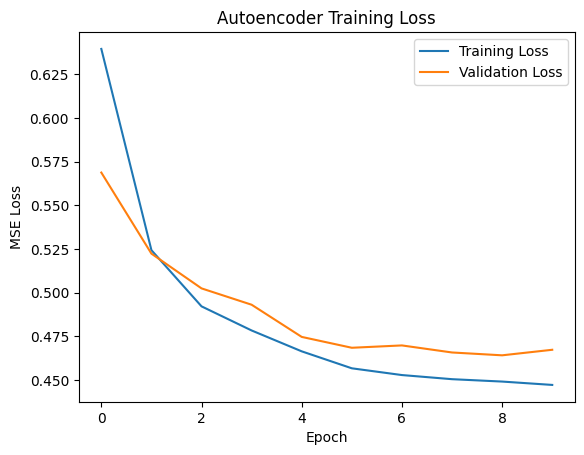

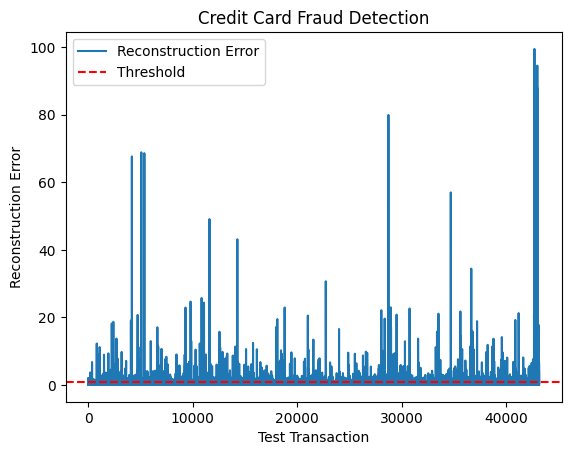

In [5]:
# Practical 3A: Credit Card Fraud Detection using Autoencoder

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Step 2: Load dataset
data = pd.read_csv("Datasets/AutoEncoder/CreditCard/creditcard.csv")

print("Dataset Shape:", data.shape)
print(data.head())

# Step 3: Separate features and labels
X = data.drop("Class", axis=1)
y = data["Class"]

# Step 4: Separate normal and fraud transactions
normal_data = X[y == 0]
fraud_data = X[y == 1]

# Split normal data into training, validation and testing
X_train, X_temp = train_test_split(
    normal_data, test_size=0.30, random_state=42
)

X_val, X_normal_test = train_test_split(
    X_temp, test_size=0.50, random_state=42
)

# Step 5: Scale the data
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_normal_test = scaler.transform(X_normal_test)
X_fraud = scaler.transform(fraud_data)

# Step 6: Prepare testing data
X_test = np.concatenate([X_normal_test, X_fraud])

y_test = np.concatenate([
    np.zeros(len(X_normal_test)),
    np.ones(len(X_fraud))
])

# Step 7: Build Autoencoder
input_layer = Input(shape=(X_train.shape[1],))

encoded = Dense(16, activation="relu")(input_layer)
encoded = Dense(8, activation="relu")(encoded)

decoded = Dense(16, activation="relu")(encoded)
output_layer = Dense(X_train.shape[1], activation="linear")(decoded)

autoencoder = Model(input_layer, output_layer)

# Step 8: Compile model
autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Step 9: Train model using normal transactions
history = autoencoder.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, X_val)
)

# Step 10: Calculate validation reconstruction errors
val_predictions = autoencoder.predict(X_val, verbose=0)

val_errors = np.mean((X_val - val_predictions) ** 2, axis=1)

# Step 11: Set threshold
threshold = np.percentile(val_errors, 95)

print("Fraud Detection Threshold:", threshold)

# Step 12: Detect fraud in test data
test_predictions = autoencoder.predict(X_test, verbose=0)

test_errors = np.mean((X_test - test_predictions) ** 2, axis=1)

y_pred = (test_errors > threshold).astype(int)

# Step 13: Evaluate model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 14: Plot training and validation loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

plt.plot(test_errors, label="Reconstruction Error")

plt.axhline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.title("Credit Card Fraud Detection")
plt.xlabel("Test Transaction")
plt.ylabel("Reconstruction Error")

plt.legend()
plt.show()

(284807, 31)
Epoch 1/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 14s 2ms/step - loss: 0.7442 - mae: 0.5784 - val_loss: 0.5463 - val_mae: 0.4881
Epoch 2/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - loss: 0.5253 - mae: 0.4799 - val_loss: 0.4755 - val_mae: 0.4569
Epoch 3/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 0.4796 - mae: 0.4541 - val_loss: 0.4670 - val_mae: 0.4423
Epoch 4/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 0.4665 - mae: 0.4420 - val_loss: 0.4626 - val_mae: 0.4342
Epoch 5/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 0.4571 - mae: 0.4356 - val_loss: 0.4639 - val_mae: 0.4272
Epoch 6/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 0.4520 - mae: 0.4276 - val_loss: 0.4622 - val_mae: 0.4223
Epoch 7/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 13s 2ms/step - loss: 0.4521 - mae: 0.4230 - val_loss: 0.4672 - val_mae: 0.4220
Epoch 8/10
6220/6220 ━━━━━━━━━━━━━━━━━━━━ 12s 2ms/step - loss: 0.4474 - mae: 0.4191 - val_loss: 0.4649 - val_mae: 0.4162
Epoch 9/10
6220/622

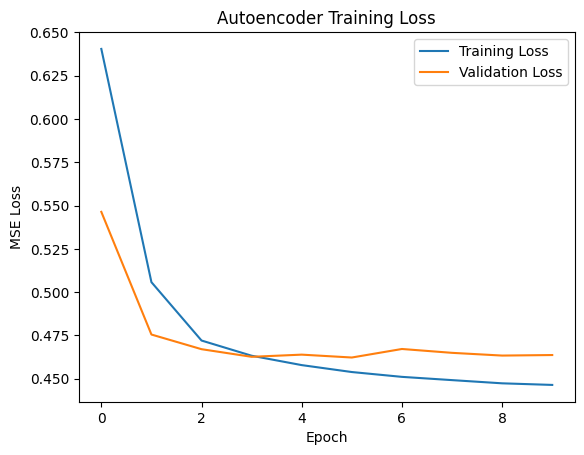

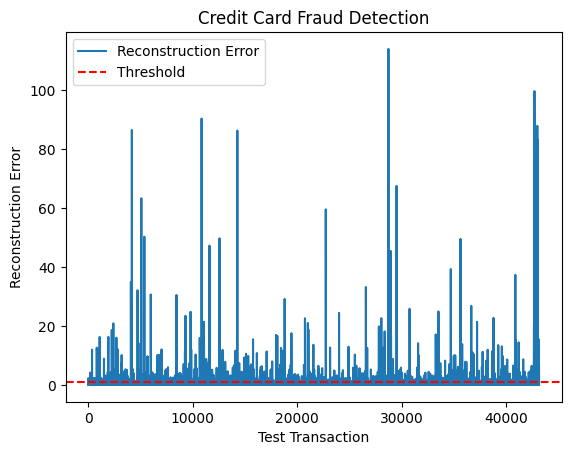

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import pandas as pd

data = pd.read_csv("Datasets/AutoEncoder/CreditCard/creditcard.csv")

print(data.shape)
data.head()

X = data.drop("Class", axis=1)
y = data["Class"]

normal_data = X[y == 0]
fraud_data = X[y == 1]

x_train, x_temp = train_test_split(normal_data, test_size=0.3, random_state=42)

x_val, x_nor = train_test_split(x_temp, test_size=0.5, random_state=42)

scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_nor = scaler.transform(x_nor)
x_fraud = scaler.transform(fraud_data)

x_test = np.concatenate([x_nor, x_fraud])

y_test = np.concatenate([
    np.zeros(len(x_nor)),
    np.ones(len(x_fraud))
])

input_layer = tf.keras.layers.Input(shape=(x_train.shape[1],))

encoded = tf.keras.layers.Dense(16, activation='relu')(input_layer)
encoded = tf.keras.layers.Dense(8, activation='relu')(encoded)

decoded = tf.keras.layers.Dense(16, activation='relu')(encoded)
output_layer = tf.keras.layers.Dense(x_train.shape[1], activation='linear')(decoded)

autoencoder = tf.keras.models.Model(input_layer, output_layer)

autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=32,
    validation_data=(x_val, x_val)
)

val_pred = autoencoder.predict(x_val, verbose=0)

val_errors = np.mean((x_val - val_pred) ** 2, axis=1)

threshold = np.percentile(val_errors, 95)
print("Threshold: ", threshold)

test_pred = autoencoder.predict(x_test, verbose=0)

test_errors = np.mean((x_test - test_pred) ** 2, axis=1)

y_pred = (test_errors > threshold).astype(int)

print("Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred))

print("Classification Report: ")
print(classification_report(y_test, y_pred))

plt.plot(history.history['loss'], label="Training Loss")
plt.plot(history.history['val_loss'], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

plt.plot(test_errors, label="Reconstruction Error")

plt.axhline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.title("Credit Card Fraud Detection")
plt.xlabel("Test Transaction")
plt.ylabel("Reconstruction Error")

plt.legend()
plt.show()